# Member 2 — Exploratory data analysis

This notebook describes the cleaned San José 311 illegal-dumping requests and investigates data quality, time patterns, reporting channels, fixed-district differences, and unusually high reporting weeks. **One row is one reported 311 service request**, not necessarily one distinct dumping event. Unreported incidents are absent, and multiple reports can describe related conditions.

### Time-split safety
- The full 2018–2025 file is used only for labeled inventory and missingness checks.
- Forecasting-oriented trends, geography, and anomaly screening use **2018–2024 only**.
- The 2025 final-test period does not influence anomaly thresholds, features, or modeling conclusions.
- Timestamps are provisionally interpreted as San José local wall-clock time, matching the team convention.

In [1]:
from pathlib import Path
from io import BytesIO
import json
import sys
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display, Image

root = Path.cwd().resolve()
while not (root / 'src' / 'demand_forecasting.py').exists():
    if root == root.parent:
        raise RuntimeError('Run this notebook from within the project repository.')
    root = root.parent
sys.path.insert(0, str(root / 'src'))
from demand_forecasting import assign_districts

def display_figure(fig, dpi=135):
    """Embed a PNG without creating a separate figure file."""
    fig.tight_layout()
    buffer = BytesIO()
    fig.savefig(buffer, format='png', dpi=dpi, bbox_inches='tight')
    display(Image(data=buffer.getvalue()))
    plt.close(fig)

data_path = root / 'data/processed/illegal_dumping_cleaned.csv'
dictionary_path = root / 'data/processed/data_dictionary.csv'
boundary_path = root / 'data/reference/council_districts_snapshot.geojson'
audit_path = root / 'results/demand_forecasting/location_audit.csv'
required = [data_path, dictionary_path, boundary_path, audit_path]
missing_files = [str(path) for path in required if not path.exists()]
if missing_files:
    raise FileNotFoundError(f'Required local files are missing: {missing_files}')

requests = pd.read_csv(data_path, dtype={'request_id': 'string'}, low_memory=False)
dictionary = pd.read_csv(dictionary_path)
created = pd.to_datetime(requests['date_created'], errors='coerce')
updated = pd.to_datetime(requests['date_last_updated'], errors='coerce')
requests['date_created'] = created
requests['date_last_updated'] = updated
requests['latitude'] = pd.to_numeric(requests['latitude'], errors='coerce')
requests['longitude'] = pd.to_numeric(requests['longitude'], errors='coerce')

overview = pd.Series({
    'rows': len(requests), 'columns': requests.shape[1],
    'unique_request_ids': requests['request_id'].nunique(),
    'duplicate_request_ids': int(requests['request_id'].duplicated().sum()),
    'exact_duplicate_rows': int(requests.duplicated().sum()),
    'invalid_or_missing_creation_dates': int(created.isna().sum()),
    'invalid_or_missing_update_dates': int(updated.isna().sum()),
    'creation_date_min': created.min(), 'creation_date_max': created.max(),
    'update_before_creation': int((updated < created).sum()),
    'source_year_date_mismatches': int((requests['source_year'] != created.dt.year).sum()),
}, name='value')
display(overview.to_frame())
display(dictionary)
display(requests.dtypes.rename('loaded_dtype').to_frame())
annual_all = requests.groupby(created.dt.year.rename('year')).size().rename('reported_requests')
display(annual_all.to_frame())
print('INVENTORY ONLY: the annual table includes reserved 2025 and is not used for later decisions.')
assert requests.shape == (213_431, 11)
assert requests['request_id'].is_unique and created.notna().all()
assert int((requests['source_year'] != created.dt.year).sum()) == 0

development = requests.loc[created.between('2018-01-01', '2024-12-31 23:59:59')].copy()
reserved_test = requests.loc[created.dt.year.eq(2025)].copy()
development['year'] = development['date_created'].dt.year
development['month_start'] = development['date_created'].dt.to_period('M').dt.to_timestamp()
development['calendar_month'] = development['date_created'].dt.month
development['day_of_week'] = development['date_created'].dt.day_name()
display(pd.Series({'development_2018_2024': len(development), 'reserved_2025': len(reserved_test),
                   '2025_rows_in_development': int(development['year'].eq(2025).sum())}, name='rows').to_frame())
assert len(development) == 181_326 and len(reserved_test) == 32_105
assert len(development) + len(reserved_test) == len(requests)

,value
rows,213431
columns,11
unique_request_ids,213431
duplicate_request_ids,0
exact_duplicate_rows,0
invalid_or_missing_creation_dates,0
invalid_or_missing_update_dates,0
creation_date_min,2018-01-01 06:23:20
creation_date_max,2025-12-31 20:08:45
update_before_creation,0


,field,type,definition_and_rule
0,request_id,string,Unique 311 incident identifier; blank IDs excl...
1,status,string,"Source status, retained for downstream analysis."
2,source,string,How the request was submitted.
3,category,string,Original category label.
4,service_type,string,Canonical label set to Illegal Dumping after f...
5,latitude/longitude,numeric,Coordinates; outside San José plausibility bou...
6,date_created,datetime,Parsed source creation timestamp; invalid or m...
7,date_last_updated,datetime,Parsed source update timestamp; not treated as...
8,department,string,Source department.
9,source_year,integer,Annual file year used for coverage auditing.


,loaded_dtype
request_id,string[python]
status,object
source,object
category,object
service_type,object
latitude,float64
longitude,float64
date_created,datetime64[ns]
date_last_updated,datetime64[ns]
department,object


,reported_requests
year,
2018,22709
2019,24489
2020,26839
2021,27540
2022,22711
2023,27129
2024,29909
2025,32105


INVENTORY ONLY: the annual table includes reserved 2025 and is not used for later decisions.


,rows
development_2018_2024,181326
reserved_2025,32105
2025_rows_in_development,0


## A–B. Dataset quality and missing values

EDA begins by checking whether essential fields are present. Missing request IDs, creation times, or coordinates would block identification, time aggregation, or mapping. Missing original `category` is different: the cleaned handoff already has canonical `service_type = Illegal Dumping`, so category absence may be structural across source systems. Nothing is filled with an invented value.

This is an all-years quality inventory. `<missing source>` is only a display label and is never written back to the data. `date_last_updated` remains an update field, not a verified completion time.

,missing_count,missing_percent
category,208566,97.720575
department,115,0.053882
source,1,0.000469
request_id,0,0.000000
status,0,0.000000
service_type,0,0.000000
latitude,0,0.000000
longitude,0,0.000000
date_created,0,0.000000
date_last_updated,0,0.000000


,category,department,source
year,,,
2018,99.92,0.05,0.0
2019,80.24,0.27,0.0
2020,100.00,0.10,0.0
2021,100.00,0.02,0.0
2022,100.00,0.02,0.0
2023,99.99,0.00,0.0
2024,100.00,0.00,0.0
2025,99.99,0.00,0.0


,records,category_missing_percent,department_missing_percent
source_display,,,
Public API,75239,94.18,0.08
VBCS Web,49931,99.99,0.00
SFDC-DOT,35518,100.00,0.00
End-User Pages,26230,100.00,0.03
End-User pages,16684,98.32,0.19
CX Console,5006,96.44,0.02
Agent desktop,3715,99.97,0.00
Web Console,970,97.63,0.93
Live Chat,71,100.00,0.00


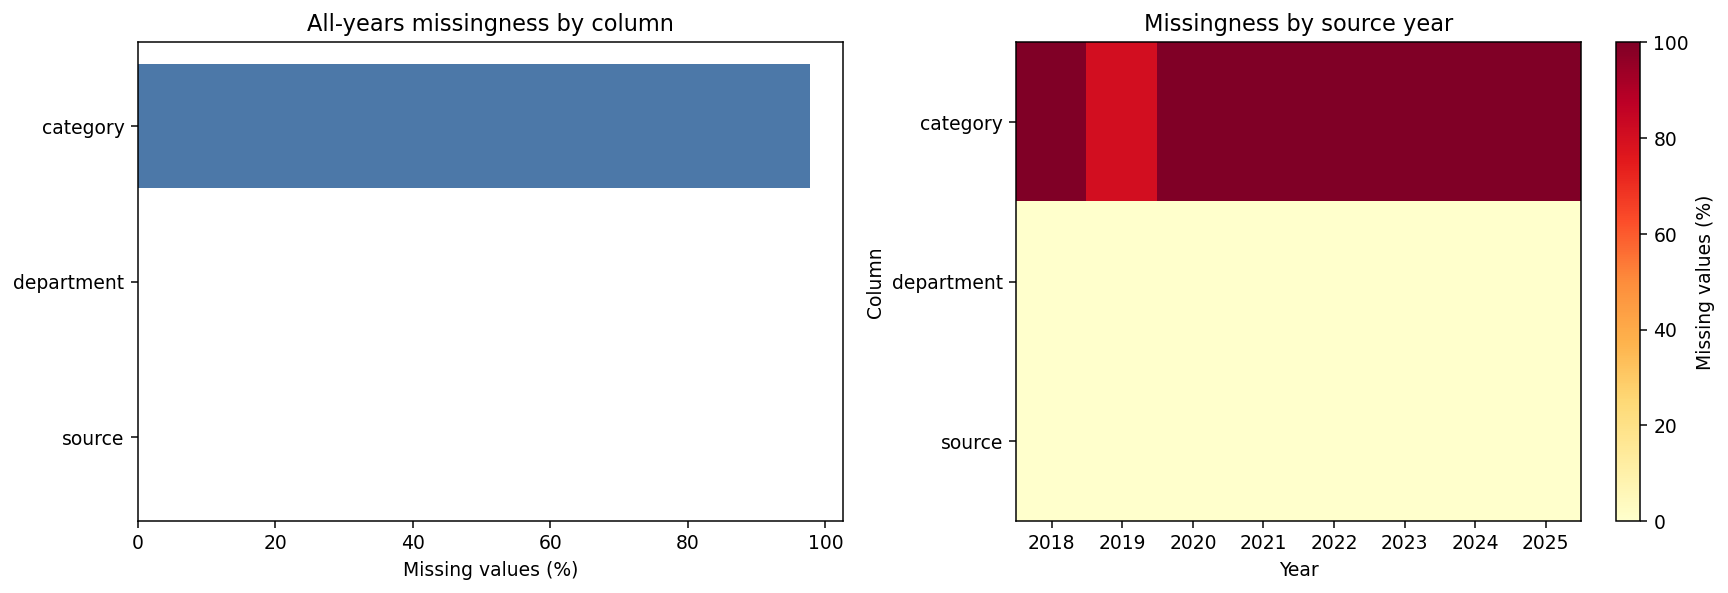

Original category is missing in 97.7% of rows.
Request ID, creation time, latitude, and longitude are complete in the cleaned handoff.


In [2]:
missing_summary = pd.DataFrame({'missing_count': requests.isna().sum(),
                                'missing_percent': 100 * requests.isna().mean()})
missing_summary = missing_summary.sort_values('missing_percent', ascending=False)
display(missing_summary)
missing_columns = missing_summary.index[missing_summary['missing_count'].gt(0)].tolist()
missing_by_year = (requests.assign(year=requests['date_created'].dt.year)
                   .groupby('year')[missing_columns]
                   .agg(lambda values: 100 * values.isna().mean()))
display(missing_by_year.round(2))
source_display = requests['source'].fillna('<missing source>')
missing_by_channel = (requests.assign(source_display=source_display)
    .groupby('source_display')
    .agg(records=('request_id', 'size'),
         category_missing_percent=('category', lambda values: 100 * values.isna().mean()),
         department_missing_percent=('department', lambda values: 100 * values.isna().mean()))
    .sort_values('records', ascending=False))
display(missing_by_channel.round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
nonzero = missing_summary.loc[missing_summary['missing_count'].gt(0)].sort_values('missing_percent')
axes[0].barh(nonzero.index, nonzero['missing_percent'], color='#4C78A8')
axes[0].set(title='All-years missingness by column', xlabel='Missing values (%)')
image = axes[1].imshow(missing_by_year.T, aspect='auto', cmap='YlOrRd', vmin=0, vmax=100)
axes[1].set(title='Missingness by source year', xlabel='Year', ylabel='Column')
axes[1].set_xticks(range(len(missing_by_year.index)), missing_by_year.index)
axes[1].set_yticks(range(len(missing_by_year.columns)), missing_by_year.columns)
fig.colorbar(image, ax=axes[1], label='Missing values (%)')
display_figure(fig)
print(f"Original category is missing in {missing_summary.loc['category', 'missing_percent']:.1f}% of rows.")
print('Request ID, creation time, latitude, and longitude are complete in the cleaned handoff.')

## C–D. Annual, monthly, weekday, and calendar-month patterns

All plots below use development data through 2024 only. They measure reports received—not verified incident occurrence. Changes can reflect reporting-system adoption, channel access, public behavior, definitions, or source coverage. A creation weekday describes when someone submitted a report and may differ from the incident day.

,reported_requests
year,
2018,22709
2019,24489
2020,26839
2021,27540
2022,22711
2023,27129
2024,29909


,reported_requests
month,
2021-06-01,3575
2021-07-01,3352
2024-01-01,3012
2020-05-01,2831
2024-09-01,2782
2020-01-01,2769
2024-08-01,2755
2024-04-01,2715
2024-07-01,2713


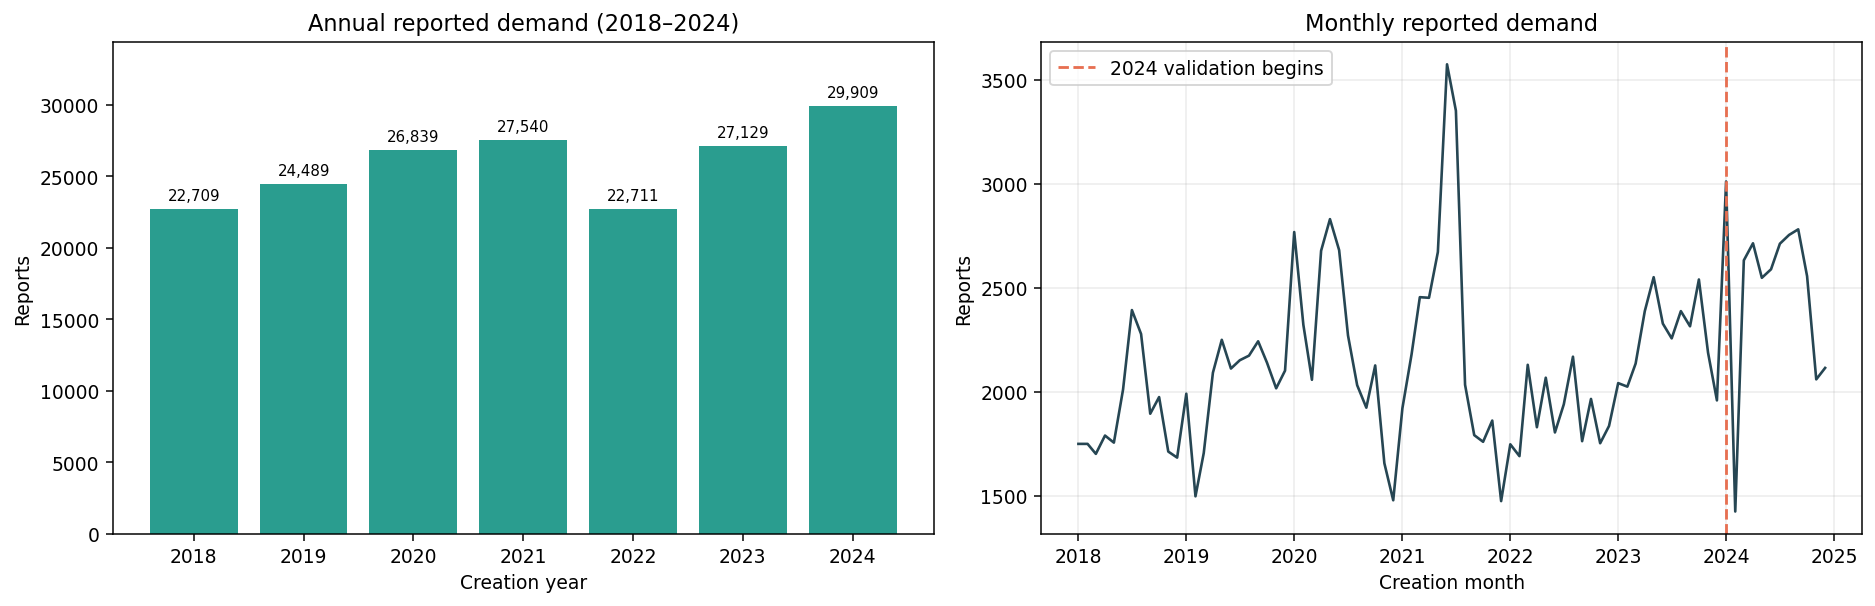

2024 reporting volume was 31.7% above 2018; this is descriptive, not causal.
Highest development month: June 2021 with 3,575 reports.


In [3]:
annual = development.groupby('year').size().rename('reported_requests')
monthly = development.groupby('month_start').size().rename('reported_requests')
monthly = monthly.reindex(pd.date_range('2018-01-01', '2024-12-01', freq='MS'), fill_value=0)
display(annual.to_frame())
display(monthly.nlargest(10).rename_axis('month').to_frame())
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
bars = axes[0].bar(annual.index.astype(str), annual.values, color='#2A9D8F')
axes[0].bar_label(bars, fmt='{:,.0f}', padding=3, fontsize=8)
axes[0].set(title='Annual reported demand (2018–2024)', xlabel='Creation year', ylabel='Reports')
axes[0].set_ylim(0, annual.max() * 1.15)
axes[1].plot(monthly.index, monthly.values, color='#264653', linewidth=1.4)
axes[1].axvline(pd.Timestamp('2024-01-01'), color='#E76F51', linestyle='--', label='2024 validation begins')
axes[1].set(title='Monthly reported demand', xlabel='Creation month', ylabel='Reports')
axes[1].grid(alpha=0.25)
axes[1].legend()
display_figure(fig)
change = 100 * (annual.loc[2024] / annual.loc[2018] - 1)
peak_month = monthly.idxmax()
print(f'2024 reporting volume was {change:.1f}% above 2018; this is descriptive, not causal.')
print(f'Highest development month: {peak_month:%B %Y} with {monthly.max():,} reports.')

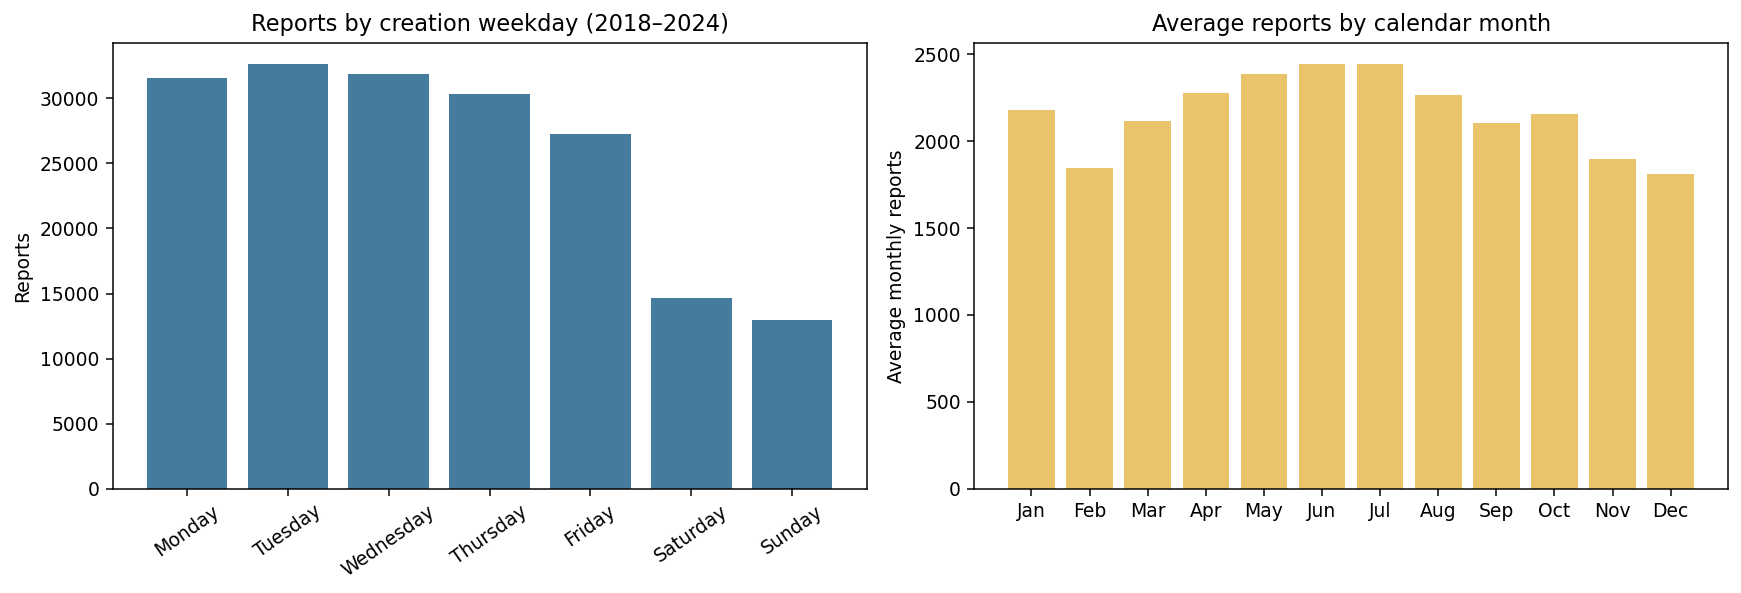

Most common creation weekday: Tuesday (32,657 reports).
Highest average calendar month: Jun.


In [4]:
weekday_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
weekday_counts = development['day_of_week'].value_counts().reindex(weekday_order)
month_labels = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
month_average = (development.groupby(['year', 'calendar_month']).size()
                 .groupby('calendar_month').mean().reindex(range(1, 13)))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].bar(weekday_order, weekday_counts.values, color='#457B9D')
axes[0].set(title='Reports by creation weekday (2018–2024)', ylabel='Reports')
axes[0].tick_params(axis='x', rotation=35)
axes[1].bar(month_labels, month_average.values, color='#E9C46A')
axes[1].set(title='Average reports by calendar month', ylabel='Average monthly reports')
display_figure(fig)
print(f'Most common creation weekday: {weekday_counts.idxmax()} ({weekday_counts.max():,} reports).')
print(f'Highest average calendar month: {month_labels[int(month_average.values.argmax())]}.')

## E. Reporting-channel analysis

Channels describe how requests entered 311. Similar-looking labels remain separate because the repository does not prove they are the same operational system. A trimmed/lowercase comparison only identifies proposed normalization candidates; it does not modify the data. For chart readability, exact labels outside the seven largest are explicitly grouped as `Other exact labels (chart only)`.

,reported_requests
source,
Public API,75239
VBCS Web,30281
End-User Pages,26230
SFDC-DOT,24583
End-User pages,16684
CX Console,5006
Agent desktop,2237
Web Console,970
Web,42


,possible_normalization_candidates
comparison_key,
end-user pages,"[End-User Pages, End-User pages]"


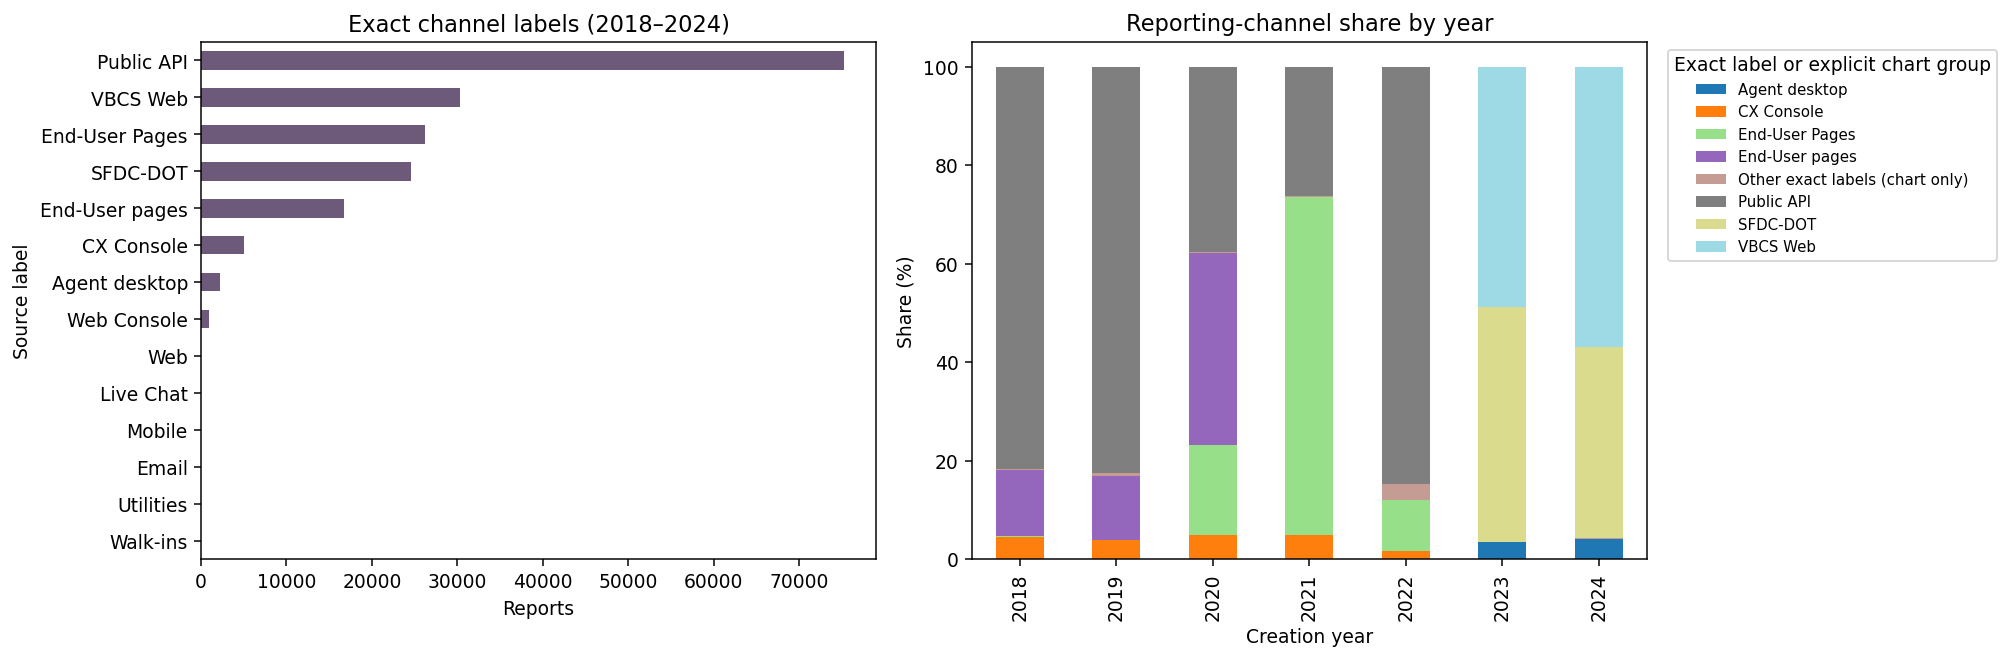

Most common exact channel: Public API (75,239 reports).
Normalization remains a proposal; no channel labels were changed.


In [5]:
development_source = development['source'].fillna('<missing source>')
source_counts = development_source.value_counts().rename('reported_requests')
display(source_counts.to_frame())
variant_frame = pd.DataFrame({'exact_label': requests['source'].dropna().unique()})
variant_frame['comparison_key'] = variant_frame['exact_label'].str.strip().str.casefold()
variants = variant_frame.groupby('comparison_key')['exact_label'].agg(lambda values: sorted(values.unique()))
display(variants[variants.map(len).gt(1)].rename('possible_normalization_candidates').to_frame())
top_labels = source_counts.head(7).index.tolist()
chart_source = development_source.where(development_source.isin(top_labels), 'Other exact labels (chart only)')
shares = pd.crosstab(development['year'], chart_source)
shares = 100 * shares.div(shares.sum(axis=1), axis=0)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
source_counts.sort_values().plot.barh(ax=axes[0], color='#6D597A')
axes[0].set(title='Exact channel labels (2018–2024)', xlabel='Reports', ylabel='Source label')
shares.plot.bar(stacked=True, ax=axes[1], colormap='tab20')
axes[1].set(title='Reporting-channel share by year', xlabel='Creation year', ylabel='Share (%)')
axes[1].legend(title='Exact label or explicit chart group', bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
display_figure(fig)
print(f'Most common exact channel: {source_counts.index[0]} ({source_counts.iloc[0]:,} reports).')
print('Normalization remains a proposal; no channel labels were changed.')

## F. District-level reported demand

A spatial join attaches a district by checking which polygon covers each request point. We reuse `assign_districts()` and preserve Phase 1 exclusions: only exactly one match enters district totals. Raw counts are not per-capita rates; districts differ in population, area, land use, and reporting access. The current/2021 map is also provisional retrospective geography for earlier years.

,requests
development_requests,181326
uniquely_mapped,180863
unmatched_preserved,463
multiple_matches,0


,reported_requests,share_percent
district,,
1,16439,9.09
2,18750,10.37
3,38654,21.37
4,12205,6.75
5,21991,12.16
6,16219,8.97
7,23340,12.90
8,12242,6.77
9,13621,7.53


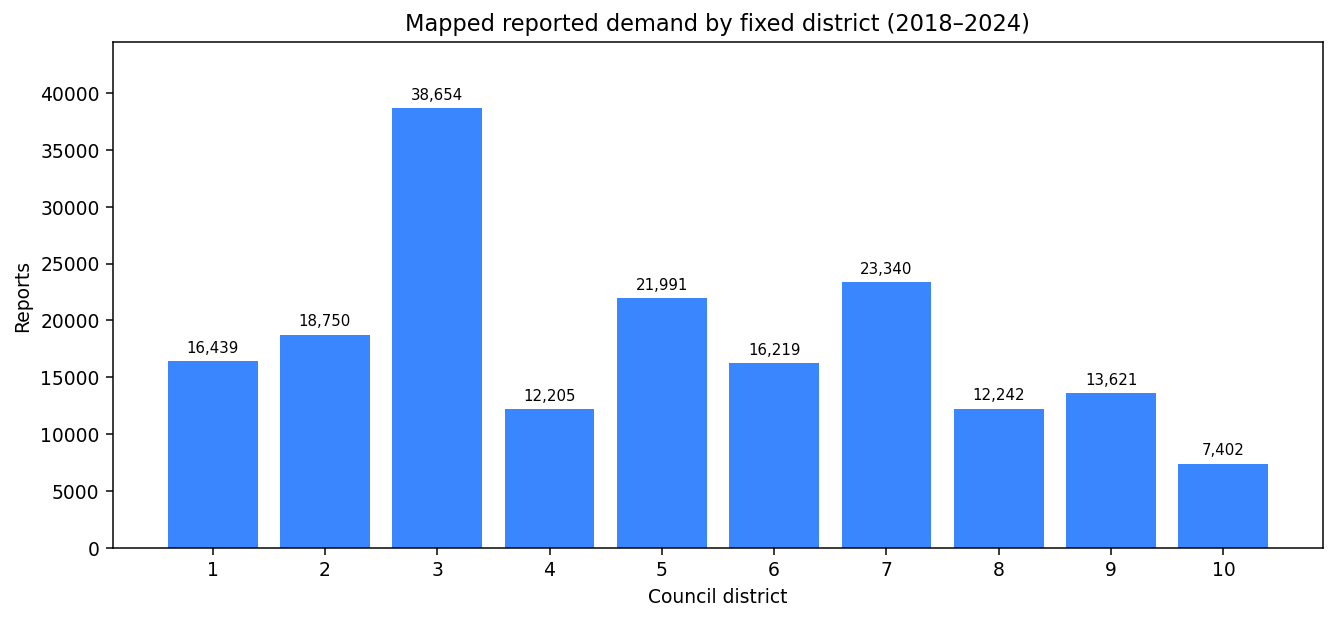

District 3 has the largest raw mapped count; no population adjustment was applied.
VERIFIED: mapping exactly matches Phase 1 and the committed location audit.


In [6]:
geojson = json.loads(boundary_path.read_text(encoding='utf-8'))
mapped = assign_districts(development, geojson)
mapping_summary = pd.Series({
    'development_requests': len(mapped),
    'uniquely_mapped': int(mapped['location_matches'].eq(1).sum()),
    'unmatched_preserved': int(mapped['location_matches'].eq(0).sum()),
    'multiple_matches': int(mapped['location_matches'].gt(1).sum()),
}, name='requests')
display(mapping_summary.to_frame())
reproduced_audit = (mapped.groupby([mapped['date_created'].dt.year.rename('year'), 'location_matches'])
                    .size().rename('requests').reset_index()
                    .sort_values(['year', 'location_matches']).reset_index(drop=True))
reported_audit = (pd.read_csv(audit_path).sort_values(['year', 'location_matches']).reset_index(drop=True))
pd.testing.assert_frame_equal(reproduced_audit, reported_audit, check_dtype=False)
audit_reconciled = True  # Values match; harmless CSV integer dtype differences are ignored.
assert mapping_summary.to_dict() == {'development_requests': 181326, 'uniquely_mapped': 180863,
                                     'unmatched_preserved': 463, 'multiple_matches': 0}
usable = mapped.loc[mapped['location_matches'].eq(1)].copy()
usable['month_start'] = usable['date_created'].dt.to_period('M').dt.to_timestamp()
usable['week_start'] = usable['date_created'].dt.normalize() - pd.to_timedelta(usable['date_created'].dt.dayofweek, unit='D')
district_counts = usable['district'].value_counts().sort_index().rename('reported_requests')
district_table = district_counts.to_frame()
district_table['share_percent'] = 100 * district_table['reported_requests'] / district_table['reported_requests'].sum()
display(district_table.round(2))
fig, ax = plt.subplots(figsize=(10, 4.7))
bars = ax.bar(district_table.index.astype(str), district_table['reported_requests'], color='#3A86FF')
ax.bar_label(bars, labels=[f'{value:,.0f}' for value in district_table['reported_requests']], padding=3, fontsize=8)
ax.set(title='Mapped reported demand by fixed district (2018–2024)', xlabel='Council district', ylabel='Reports')
ax.set_ylim(0, district_table['reported_requests'].max() * 1.15)
display_figure(fig)
largest = district_table['reported_requests'].idxmax()
print(f'District {largest} has the largest raw mapped count; no population adjustment was applied.')
print('VERIFIED: mapping exactly matches Phase 1 and the committed location audit.')

,mean,std,min,max,coefficient_of_variation
district,,,,,
1,44.99,18.98,9,133,0.42
2,51.33,17.57,15,114,0.34
3,105.81,32.66,44,295,0.31
4,33.42,9.94,8,67,0.30
5,60.21,26.19,19,185,0.44
6,44.41,14.27,12,90,0.32
7,63.91,20.27,16,148,0.32
8,33.52,10.67,9,72,0.32
9,37.30,59.20,5,545,1.59


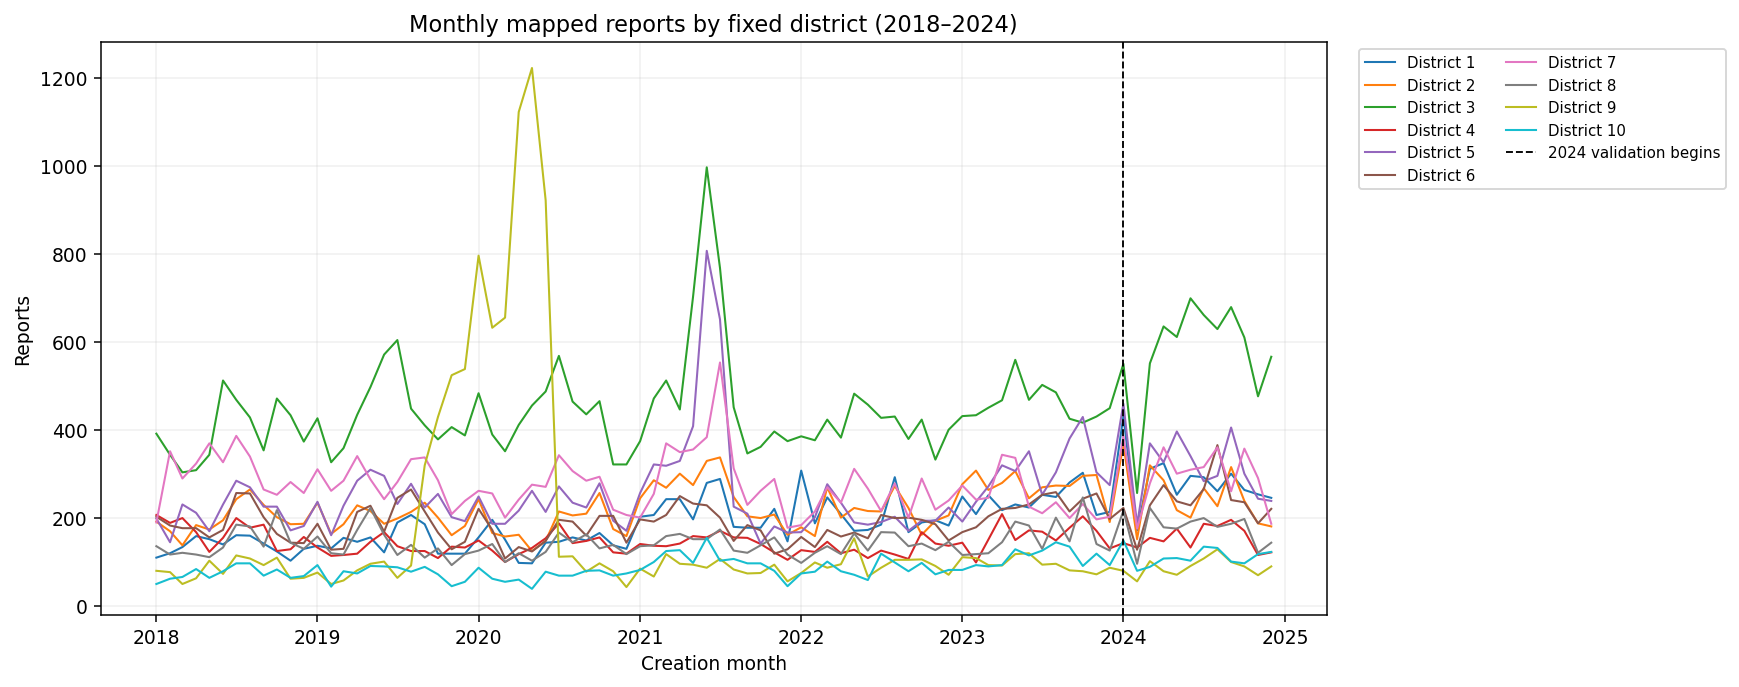

Districts differ in reporting level and variability; these are raw counts, not per-capita rates.


In [7]:
districts = sorted(int(feature['properties']['DISTRICT']) for feature in geojson['features'])
months = pd.date_range('2018-01-01', '2024-12-01', freq='MS')
month_grid = pd.MultiIndex.from_product([months, districts], names=['month_start', 'district'])
district_monthly = (usable.groupby(['month_start', 'district']).size()
                    .reindex(month_grid, fill_value=0).rename('requests').reset_index())
month_pivot = district_monthly.pivot(index='month_start', columns='district', values='requests')
weeks = pd.date_range('2018-01-01', '2024-12-23', freq='W-MON')
week_grid = pd.MultiIndex.from_product([districts, weeks], names=['district', 'week_start'])
district_weekly = (usable.groupby(['district', 'week_start']).size()
                   .reindex(week_grid, fill_value=0).rename('requests').reset_index())
variation = district_weekly.groupby('district')['requests'].agg(['mean', 'std', 'min', 'max'])
variation['coefficient_of_variation'] = variation['std'] / variation['mean']
display(variation.round(2))
fig, ax = plt.subplots(figsize=(13, 5.2))
for district in districts:
    ax.plot(month_pivot.index, month_pivot[district], linewidth=1.1, label=f'District {district}')
ax.axvline(pd.Timestamp('2024-01-01'), color='black', linestyle='--', linewidth=1, label='2024 validation begins')
ax.set(title='Monthly mapped reports by fixed district (2018–2024)', xlabel='Creation month', ylabel='Reports')
ax.grid(alpha=0.2)
ax.legend(ncol=2, bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
display_figure(fig)
print('Districts differ in reporting level and variability; these are raw counts, not per-capita rates.')

## G. Descriptive high-week screening

A complete week runs Monday through Sunday. On the continuous 2018–2024 forecasting-compatible grid, a week is flagged when its mapped total exceeds `Q3 + 1.5 × IQR`. This transparent descriptive rule is not a model and does not prove an external event. The table shows the largest contributing district and exact channel for investigation only. The threshold excludes 2025.

,value
complete_development_weeks,365.0
Q1,429.0
Q3,559.0
IQR,130.0
high_week_threshold,754.0
flagged_high_weeks,10.0
2025_weeks_used,0.0


,week_start,week_end,reported_requests,largest_contributing_district,district_requests,largest_exact_channel,channel_requests
0,2020-06-01,2020-06-07,950,9,545,End-User pages,816
1,2021-06-07,2021-06-13,899,3,295,End-User Pages,746
2,2021-06-28,2021-07-04,813,5,183,End-User Pages,678
3,2020-05-18,2020-05-24,803,9,422,End-User pages,676
4,2021-05-31,2021-06-06,798,3,253,End-User Pages,640
5,2021-07-19,2021-07-25,796,3,167,End-User Pages,689
6,2021-06-21,2021-06-27,779,5,185,End-User Pages,677
7,2021-07-26,2021-08-01,766,3,158,End-User Pages,637
8,2021-07-12,2021-07-18,763,3,203,End-User Pages,641
9,2024-07-29,2024-08-04,761,3,227,VBCS Web,425


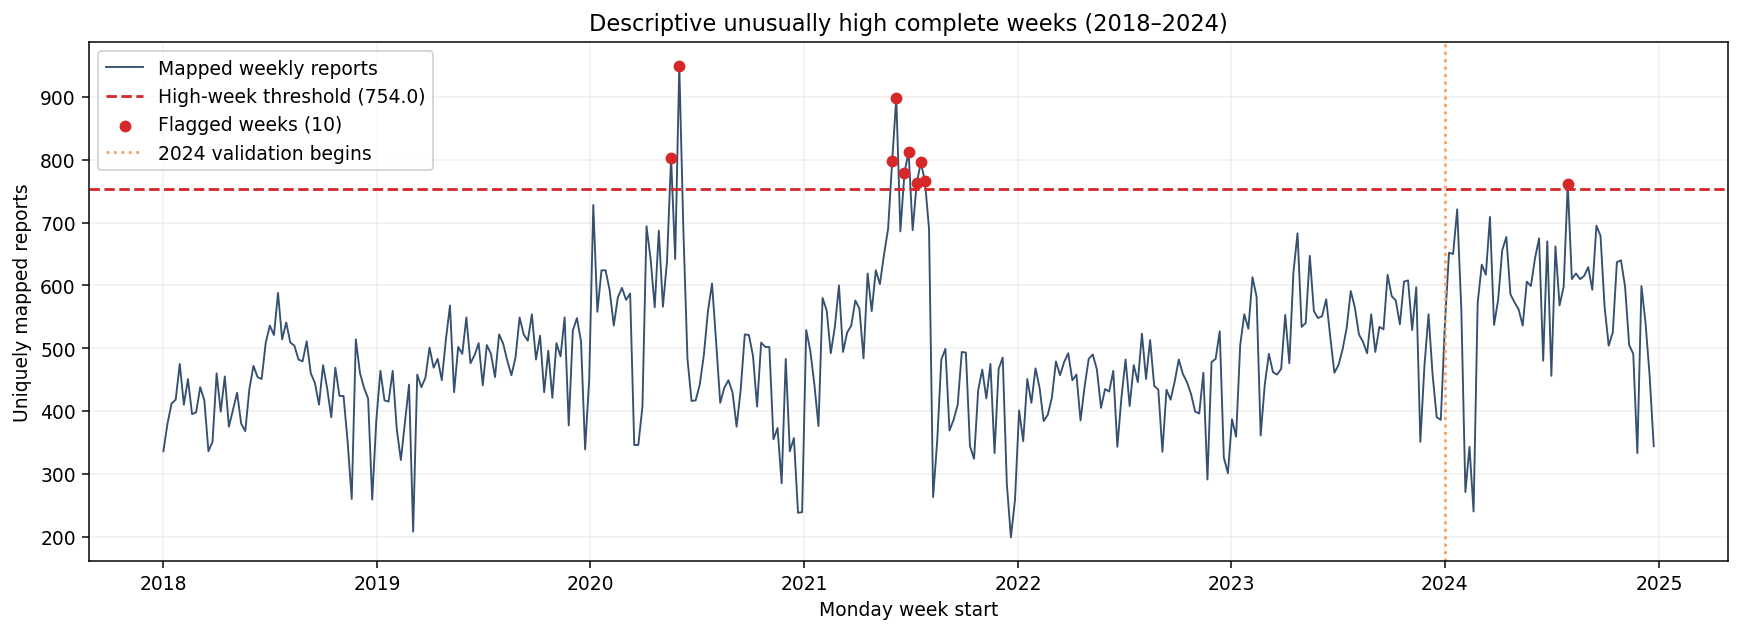

Flags identify unusual reporting volume, not confirmed dumping events or causes.


In [8]:
complete_weeks = pd.date_range('2018-01-01', '2024-12-23', freq='W-MON')
weekly_city = usable.groupby('week_start').size().reindex(complete_weeks, fill_value=0).rename('reported_requests')
q1, q3 = weekly_city.quantile([0.25, 0.75])
iqr = q3 - q1
threshold = q3 + 1.5 * iqr
high_weeks = weekly_city.loc[weekly_city.gt(threshold)].sort_values(ascending=False)
anomaly_rows = []
for week_start, count in high_weeks.items():
    rows = usable.loc[usable['week_start'].eq(week_start)]
    district_breakdown = rows['district'].value_counts()
    channel_breakdown = rows['source'].fillna('<missing source>').value_counts()
    anomaly_rows.append({'week_start': week_start, 'week_end': week_start + pd.Timedelta(days=6),
                         'reported_requests': int(count),
                         'largest_contributing_district': int(district_breakdown.index[0]),
                         'district_requests': int(district_breakdown.iloc[0]),
                         'largest_exact_channel': channel_breakdown.index[0],
                         'channel_requests': int(channel_breakdown.iloc[0])})
anomaly_table = pd.DataFrame(anomaly_rows)
display(pd.Series({'complete_development_weeks': len(weekly_city), 'Q1': q1, 'Q3': q3, 'IQR': iqr,
                   'high_week_threshold': threshold, 'flagged_high_weeks': len(high_weeks),
                   '2025_weeks_used': int((weekly_city.index.year == 2025).sum())}, name='value').to_frame())
display(anomaly_table)
fig, ax = plt.subplots(figsize=(13, 4.8))
ax.plot(weekly_city.index, weekly_city.values, color='#355070', linewidth=1, label='Mapped weekly reports')
ax.axhline(threshold, color='#D62828', linestyle='--', label=f'High-week threshold ({threshold:.1f})')
ax.scatter(high_weeks.index, high_weeks.values, color='#D62828', s=28, zorder=3, label=f'Flagged weeks ({len(high_weeks)})')
ax.axvline(pd.Timestamp('2024-01-01'), color='#F4A261', linestyle=':', label='2024 validation begins')
ax.set(title='Descriptive unusually high complete weeks (2018–2024)', xlabel='Monday week start',
       ylabel='Uniquely mapped reports')
ax.grid(alpha=0.2)
ax.legend()
display_figure(fig)
assert weekly_city.index.max() == pd.Timestamp('2024-12-23')
assert not (weekly_city.index.year == 2025).any()
print('Flags identify unusual reporting volume, not confirmed dumping events or causes.')

## H. Conclusions, limits, and next phase

### Interpretation limits
- Reports measure 311 use, not all illegal-dumping incidents.
- Reporting weekday may differ from incident day.
- Channel labels and usage changed; similar labels were not silently merged.
- Original `category` is sparse while canonical `service_type` is present.
- Raw district counts are not adjusted for population, area, land use, or channel access.
- One current/2021 map is provisional retrospective geography for older requests.
- Annual source completeness and zero-demand interpretation still need team confirmation.
- Anomaly flags identify unusual reporting volume but do not explain causes.

### Remaining feature-engineering work
The feature-engineering and comparison notebooks evaluated calendar and historical count features on identical 2024 validation rows.

In [9]:
final_checks = pd.Series({
    'cleaned_rows_reconciled': len(requests) == 213_431,
    'request_ids_unique': requests['request_id'].is_unique,
    'development_rows_reconciled': len(development) == 181_326,
    'reserved_2025_rows_reconciled': len(reserved_test) == 32_105,
    'mapped_rows_reconciled': len(usable) == 180_863,
    'geographic_audit_reconciled': audit_reconciled,
    'anomaly_analysis_excludes_2025': not (weekly_city.index.year == 2025).any(),
    'complete_week_grid_ends_2024_12_23': weekly_city.index.max() == pd.Timestamp('2024-12-23'),
}, name='passed')
display(final_checks.to_frame())
assert final_checks.all()
print('All EDA reconciliation, geography, and time-split checks passed.')

,passed
cleaned_rows_reconciled,True
request_ids_unique,True
development_rows_reconciled,True
reserved_2025_rows_reconciled,True
mapped_rows_reconciled,True
geographic_audit_reconciled,True
anomaly_analysis_excludes_2025,True
complete_week_grid_ends_2024_12_23,True


All EDA reconciliation, geography, and time-split checks passed.
